### Partie V

In [115]:
import numpy as np  
import matplotlib.pyplot as plt  

In [116]:
A = np.array([0,0,5]) 
B = np.array([1,-2,0.4])
Va = np.array([0.2,0,0])
Vb = np.array([0.5,0,0])
Ka = np.array([0,0,0])
Kb = np.array([0,0,0])

tf = 10 #s
t = np.linspace(0,tf,tf*100)

In [117]:
def calcul_coeffs(a,b,va,vb,ka,kb,tf):
    """
    Calcul des coefficients ai afin de déterminer les équations de trajectoire
    - Input : parametres rentrés par l'utilisateur (en x,y ou z)
    - output : retourne les coefficients    
    """
    a0,a1,a2 = a, va, ka/2
    
    D = np.array(([tf**3,tf**4,tf**5], [3*tf**2, 4*tf**3, 5*tf**4], [6*tf, 12*tf**2, 20*tf**3]))
    D_inv = np.linalg.inv(D)
    F = np.array([b-a0-a1*tf-a2*tf**2, vb-a1-a2*tf, kb-ka])

    coeffs_suivants = D_inv @ F
    a3,a4,a5 = coeffs_suivants[0], coeffs_suivants[1], coeffs_suivants[2]

    return a0,a1,a2,a3,a4,a5

def calcul_equations(c,t):
    """
    Calcul des équations de position, vitesse et accélération
    input : coefficients et temps
    output : position(t), vitesse(t), accelration(t)
    """
    position = c[0] + c[1]*t + c[2]*t**2 + c[3]*t**3 + c[4]*t**4 + c[5]*t**5
    vitesse = c[1] + 2*c[2]*t + 3*c[3]*t**2 + 4*c[4]*t**3 + 5*c[5]*t**4
    acceleration = 2*c[2] + 6*c[3]*t + 12*c[4]*t**2 + 20*c[5]*t**3

    return position, vitesse, acceleration

In [ ]:
def traj(A,B,Va,Vb,Ka,Kb,t,tf):
    """ 
    Calcul de la trajectoire
    """

    c_x = calcul_coeffs(A[0], B[0], Va[0], Vb[0], Ka[0], Kb[0], tf)
    c_y = calcul_coeffs(A[1], B[1], Va[1], Vb[1], Ka[1], Kb[1], tf)
    c_z = calcul_coeffs(A[2], B[2], Va[2], Vb[2], Ka[2], Kb[2], tf)

    pos = [[],[],[]]
    vit = [[],[],[]]
    acc = [[],[],[]]
    pos_x, vit_x, acc_x = calcul_equations(c_x,t)
    pos_y, vit_y, acc_y = calcul_equations(c_y,t)
    pos_z, vit_z, acc_z = calcul_equations(c_z, t)

    pos[0]=(pos_x)
    vit[0]=(vit_x)
    acc[0]=(acc_x)
    pos[0]=(pos_y)
    vit[1]=(vit_y)
    acc[2]=(acc_y)
    pos[0]=(pos_z)
    vit[1]=(vit_z)
    acc[2]=(acc_z)

    return pos,vit,acc

In [ ]:
def plot_traj(A,B,Va,Vb,Ka,Kb,temps,tf):
    """ 
    Calcul de la trajectoire
    """

    c_x = calcul_coeffs(A[0], B[0], Va[0], Vb[0], Ka[0], Kb[0], tf)
    c_y = calcul_coeffs(A[1], B[1], Va[1], Vb[1], Ka[1], Kb[1], tf)
    c_z = calcul_coeffs(A[2], B[2], Va[2], Vb[2], Ka[2], Kb[2], tf)

    traj_x = [[],[],[]]
    traj_y = [[],[],[]]
    traj_z = [[],[],[]]
    for t in temps:
        pos_x, vit_x, acc_x = calcul_equations(c_x,t)
        pos_y, vit_y, acc_y = calcul_equations(c_y,t)
        pos_z, vit_z, acc_z = calcul_equations(c_z, t)
        traj_x[0].append(pos_x)
        traj_x[1].append(vit_x)
        traj_x[2].append(acc_x)
        traj_y[0].append(pos_y)
        traj_y[1].append(vit_y)
        traj_y[2].append(acc_y)
        traj_z[0].append(pos_z)
        traj_z[1].append(vit_z)
        traj_z[2].append(acc_z)


    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    # Points de départ et d'arrivée
    ax.scatter(A[0], A[1], A[2], color='green', s=100, label='Départ')
    ax.scatter(B[0], B[1], B[2], color='red', s=100, label='Arrivée')


    # Tracé de la trajectoire
    #ax.plot(position['x'], position['y'], position['z'], label='Trajectoire 3D', color='b', lw=2)
    ax.plot(traj_x[0], traj_y[0], traj_z[0], label='Trajectoire 3D', color='b', lw=2)

    ax.set_title("Génération de trajectoire 3D ")
    ax.set_xlabel("Axe X")
    ax.set_ylabel("Axe Y")
    ax.set_zlabel("Axe Z")
    ax.legend()
    plt.show()


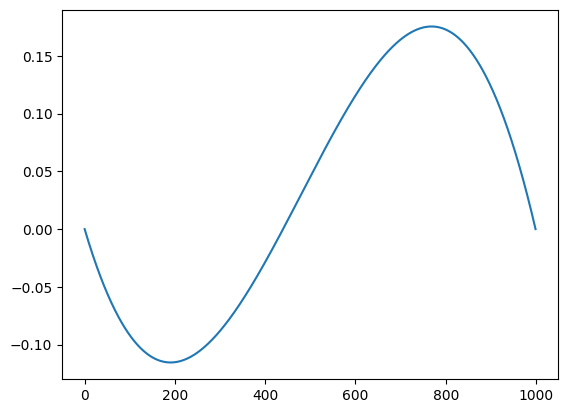

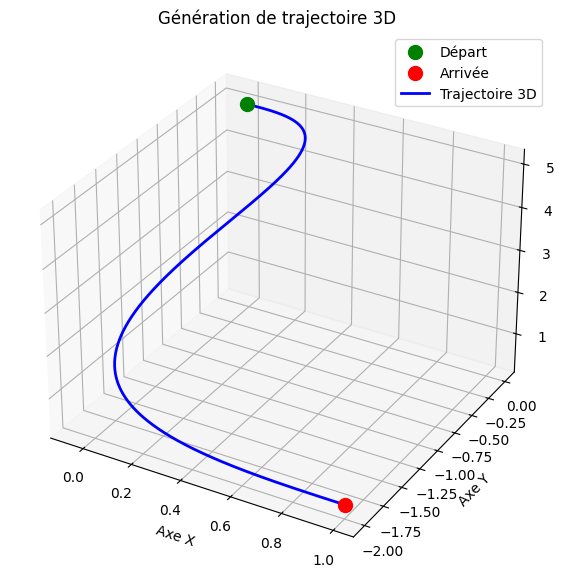

In [ ]:
plot_traj(A,B,Va,Vb,Ka,Kb,t,tf)